# Dynamic and Hybrid Conditioning for Compositional Image Retrieval

## Setup

In [2]:
import json
from math import inf
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

# from google.colab import drive
from huggingface_hub import hf_hub_download
from torchvision.datasets import CelebA
from transformers import CLIPModel, CLIPProcessor

/home/skiiyuru/learn-by-doing/conditional-image-retrieval/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
CLIP_VERSION = "openai/clip-vit-base-patch32"
HF_REPO = "skiiyuru/conditional-image-retrieval"
# CELEBA_DIR = Path("/content/drive/MyDrive/celeba")  # ← reviewer: point to your CelebA
# CELEBA_DIR = Path("data")  # ← reviewer: point to your CelebA
DATA_DIR = Path("data")
SRC_DIR = Path("src")
RESULTS_DIR = Path("results")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# DATA_DIR.mkdir(parents=True, exist_ok=True)
# SRC_DIR.mkdir(parents=True, exist_ok=True)
# RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# Mount Drive and link CelebA

In [ ]:
# drive.mount("/content/drive")

# Symlink reviewer's CelebA into ./data/celeba
# celeba_target = DATA_DIR / "celeba"
# if not celeba_target.exists():
#     celeba_target.symlink_to(CELEBA_DIR)

In [6]:
HF_FILES = [
    "celeba_evaluation.json",
    "test_img_embed_db.pt",
    "train_img_embed_db.pt",
    "attr_embed_db.pt",
    "lora_checkpoint_50.pt",
    "lora_checkpoint_100.pt",
    "train_examples_50.pt",
    "val_examples_50.pt",
    "train_examples_100.pt",
    "val_examples_100.pt",
]

In [4]:
def download_files_from_hf(repo_id, files):
    for fname in files:
        hf_hub_download(repo_id=repo_id, filename=f"src/{fname}", local_dir=".", repo_type="dataset")
        print(f"Downloaded: {fname}")

In [7]:
download_files_from_hf(HF_REPO, HF_FILES)

Downloaded: celeba_evaluation.json
Downloaded: test_img_embed_db.pt
Downloaded: train_img_embed_db.pt
Downloaded: attr_embed_db.pt
Downloaded: lora_checkpoint_50.pt
Downloaded: lora_checkpoint_100.pt
Downloaded: train_examples_50.pt
Downloaded: val_examples_50.pt
Downloaded: train_examples_100.pt
Downloaded: val_examples_100.pt


## Shared utilites

In [4]:
celeba_test = CelebA(root=DATA_DIR, split="test", download=False)
celeba_train = CelebA(root=DATA_DIR, split="train", download=False)
len(celeba_test), len(celeba_train)

(19962, 162770)

In [5]:
with open(SRC_DIR / "celeba_evaluation.json") as f:
    annotations = json.load(f)

In [6]:
attribute2idx = {name: idx for idx, name in enumerate(celeba_test.attr_names[:40])}

Helper functions for logging and evaluation.

In [ ]:
def evaluate_retrieval(retrieved_indices: list[int], ground_truth_indices: list[int], k: int, log: bool = True) -> dict:
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {f"Recall@{k}": recall_at_k, f"Precision@{k}": precision_at_k}


def initialize_scores():
    """Create a score accumulator keyed by query string."""
    scores = {}
    for ann in annotations:
        q = ann["query"]
        scores[q] = {"ref_counts": len(ann["ground_truth"])}
        for k in [1, 5, 10]:
            scores[q][f"Recall@{k}"] = 0
            scores[q][f"Precision@{k}"] = 0
    return scores


def log_result(result, query, k, scores):
    """Accumulate one retrieval result into the scores dict."""
    scores[query][f"Recall@{k}"] += result[f"Recall@{k}"]
    scores[query][f"Precision@{k}"] += result[f"Precision@{k}"]


def compute_averages(scores):
    """Convert accumulated scores into per-query averages."""
    avg = {}
    for query, vals in scores.items():
        n = vals["ref_counts"]
        avg[query] = {}
        for k in [1, 5, 10]:
            avg[query][f"Recall@{k}"] = round(vals[f"Recall@{k}"] / n, 4)
            avg[query][f"Precision@{k}"] = round(vals[f"Precision@{k}"] / n, 4)
    return avg


def compute_similarity(query, db, ref_idx, k=10):
    """Cosine similarity retrieval, excluding the reference image."""
    score = db @ query.T
    score[ref_idx] = -inf
    _, idxs = torch.sort(score, dim=0, descending=True)
    return torch.flatten(idxs[:k]).tolist()


def sum_up(attributes, *, text_db=None, model=None):
    """Sum embeddings for a list of attribute names."""
    if not attributes:
        return torch.zeros(1, 512, device=DEVICE)
    embeds = []
    for attr in attributes:
        if text_db is not None:
            embeds.append(text_db[attribute2idx[attr]].unsqueeze(0))
        elif model is not None:
            embeds.append(embed_single_attribute(model, attr))  # noqa: F821
        else:
            raise ValueError("Pass either text_db or model")
    return torch.sum(torch.cat(embeds, 0), 0, keepdim=True)


def retrieve(annotation, img_db, scores, qualitative, *, text_db=None, model=None):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes, text_db=text_db, model=model)
    negative_attributes = sum_up(negative_attributes, text_db=text_db, model=model)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs:
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for k in [1, 5, 10]:
            # result struct: {"Recall@k": 0, "Precision@k": 0}
            result = evaluate_retrieval(top_10, ground_truths, k, log=False)
            log_result(result, annotation["query"], k, scores)

        qualitative[annotation["query"]].append(
            {
                "ref_idx": idx,
                "retrieved": top_10,
                "ground_truths": ground_truths,
            }
        )


def retrieve_all(annotations, img_db, *, text_db=None, model=None):
    scores = initialize_scores()
    qualitative = {ann["query"]: [] for ann in annotations}

    for annotation in annotations:
        retrieve(annotation, img_db, scores, qualitative, text_db=text_db, model=model)

    averages = compute_averages(scores)
    return averages, qualitative


def macro_summary(averages):
    """Macro-average across all queries."""
    metrics = {}
    for k in [1, 5, 10]:
        metrics[f"Macro_Recall@{k}"] = round(np.mean([v[f"Recall@{k}"] for v in averages.values()]), 4)
        metrics[f"Macro_Precision@{k}"] = round(np.mean([v[f"Precision@{k}"] for v in averages.values()]), 4)
    return metrics


def plot_per_query(results, title, metrics=None):
    """Bar chart of per-query metrics for one or more result sets."""
    if metrics is None:
        metrics = ["Recall@1", "Recall@5", "Recall@10"]

    queries = list(results.keys())
    x = np.arange(len(queries))
    w = 0.8 / len(metrics)

    fig, ax = plt.subplots(figsize=(14, 5))
    for i, m in enumerate(metrics):
        ax.bar(x + i * w, [results[q][m] for q in queries], w, label=m)

    ax.set_xticks(x + w * (len(metrics) - 1) / 2)
    ax.set_xticklabels(queries, rotation=45, ha="right", fontsize=9)
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_qualitative(qualitative, query, n_examples=3, k=5):
    """Show reference, top-k retrieved, and ground truth for a query."""
    examples = qualitative[query][:n_examples]
    n_rows = len(examples)

    fig, axes = plt.subplots(n_rows, k + 2, figsize=(3 * (k + 2), 3 * n_rows))
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    for row, ex in enumerate(examples):
        ref_idx = ex["ref_idx"]
        retrieved = ex["retrieved"][:k]
        gt = ex["ground_truths"]
        gt_show = gt[:1]  # show first ground truth for comparison

        # Reference
        axes[row, 0].imshow(celeba_test[ref_idx][0])
        axes[row, 0].set_title(f"REF\n{ref_idx}")
        axes[row, 0].axis("off")

        # First ground truth
        if gt_show:
            axes[row, 1].imshow(celeba_test[gt_show[0]][0])
            axes[row, 1].set_title(f"GT\n{gt_show[0]}")
            axes[row, 1].axis("off")

        # Retrieved
        for col, idx in enumerate(retrieved):
            label = "CORRECT" if idx in set(gt) else "WRONG"
            axes[row, col + 2].imshow(celeba_test[idx][0])
            axes[row, col + 2].set_title(f"{idx} [{label}]")
            axes[row, col + 2].axis("off")

    axes[0, 0].set_ylabel("Examples", rotation=0, labelpad=60, va="center")
    plt.suptitle(f"Query: {query}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

## Baseline

### Methodology


CLIP (Radford et al., 2021) learns a joint embedding space where images and text 
live in the same $d$-dimensional vector space. Given a reference image with embedding 
$\mathbf{v}_{\text{ref}} \in \mathbb{R}^d$ and a set of positive and negative attribute 
text embeddings $\mathbf{t}^+_i, \mathbf{t}^-_j$, we compose the query by naïve 
Euclidean arithmetic:

$$\mathbf{q} = \mathbf{v}_{\text{ref}} + \sum_i \mathbf{t}^+_i - \sum_j \mathbf{t}^-_j$$

Retrieval is then cosine similarity between $\mathbf{q}$ and all database image 
embeddings, ranked descending, taking the top-$K$ results. The reference image is 
excluded from its own retrieval.

This baseline assumes the embedding space is flat (Euclidean) and that attributes 
compose linearly — both assumptions we will challenge in later threads.


### Embed CelebA data

In [8]:
processor = CLIPProcessor.from_pretrained(CLIP_VERSION)

model = CLIPModel.from_pretrained(CLIP_VERSION)
model = model.to(DEVICE)
model.eval()

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 12400.43it/s]


CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1e-05, eleme

In [31]:
def embed(model, inputs, type="img"):
    with torch.inference_mode():
        if type == "img":
            embeddings = model.get_image_features(inputs)
        if type == "text":
            embeddings = model.get_text_features(inputs)

        embeddings = F.normalize(embeddings.pooler_output, p=2, dim=-1)
        return embeddings


def embed_images(model, dataset, batch_size=128):
    """embeds all images in celeba dataset(train/test) and returns the resulting tensor."""

    num_imgs = len(dataset)
    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [dataset[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        inputs = inputs["pixel_values"].to(DEVICE)

        embeddings = embed(model, inputs)
        batches.append(embeddings)

    db = torch.cat(batches, dim=0)
    return db

In [48]:
def embed_attributes():
    """Embed all 40 CelebA attributes as text through CLIP's text tower."""
    text = [attr.replace("_", " ") for attr in celeba_test.attr_names[:40]]
    inputs = processor(text=text, return_tensors="pt", padding=True, truncation=True)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.inference_mode():
        embeddings = model.get_text_features(**inputs)
    return F.normalize(embeddings.pooler_output, p=2, dim=-1)

In [ ]:
# test_img_embed_db = embed_images(model, celeba_test)

torch.Size([19962, 512])

In [ ]:
# train_img_embed_db = embed_images(model, celeba_train)

In [49]:
attr_embed_db = embed_attributes()
attr_embed_db.shape

torch.Size([40, 512])

In [ ]:
# torch.save(test_img_embed_db, f"{SRC_DIR}/test_img_embed_db.pt")
# torch.save(train_img_embed_db, f"{SRC_DIR}/train_img_embed_db.pt")
# torch.save(attr_embed_db, f"{SRC_DIR}/attr_embed_db.pt")

In [9]:
test_img_embed_db = torch.load(f"{SRC_DIR}/test_img_embed_db.pt", map_location=DEVICE)
train_img_embed_db = torch.load(f"{SRC_DIR}/train_img_embed_db.pt", map_location=DEVICE)
attr_embed_db = torch.load(f"{SRC_DIR}/attr_embed_db.pt", map_location=DEVICE)
test_img_embed_db.shape, train_img_embed_db.shape, attr_embed_db.shape

(torch.Size([19962, 512]), torch.Size([162770, 512]), torch.Size([40, 512]))

### Evaluation

In [20]:
baseline_avg, baseline_qualitative = retrieve_all(annotations, test_img_embed_db, text_db=attr_embed_db)

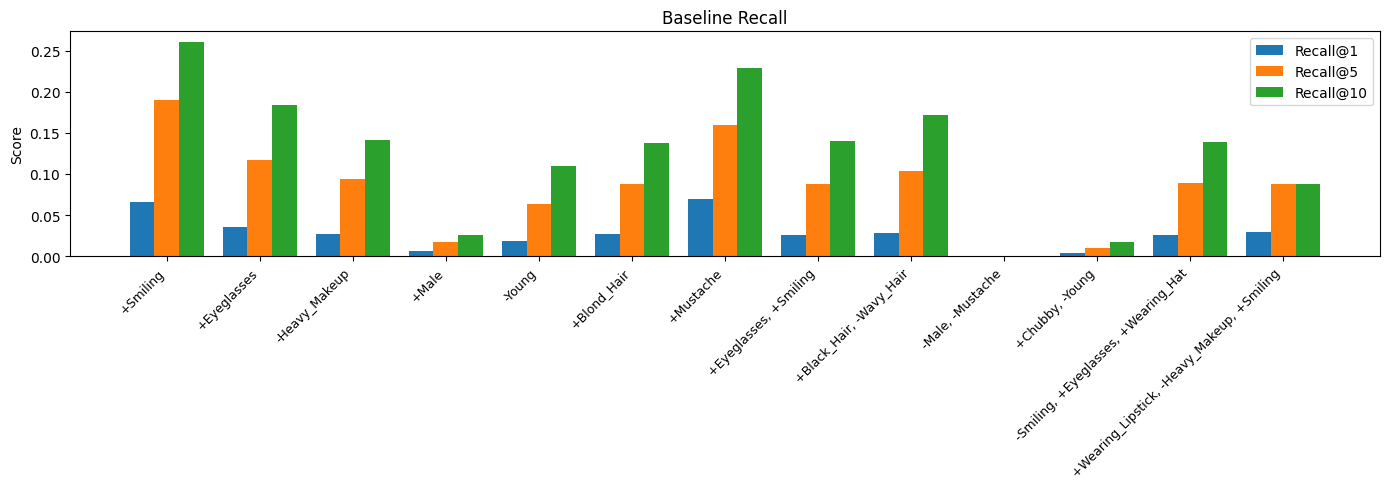

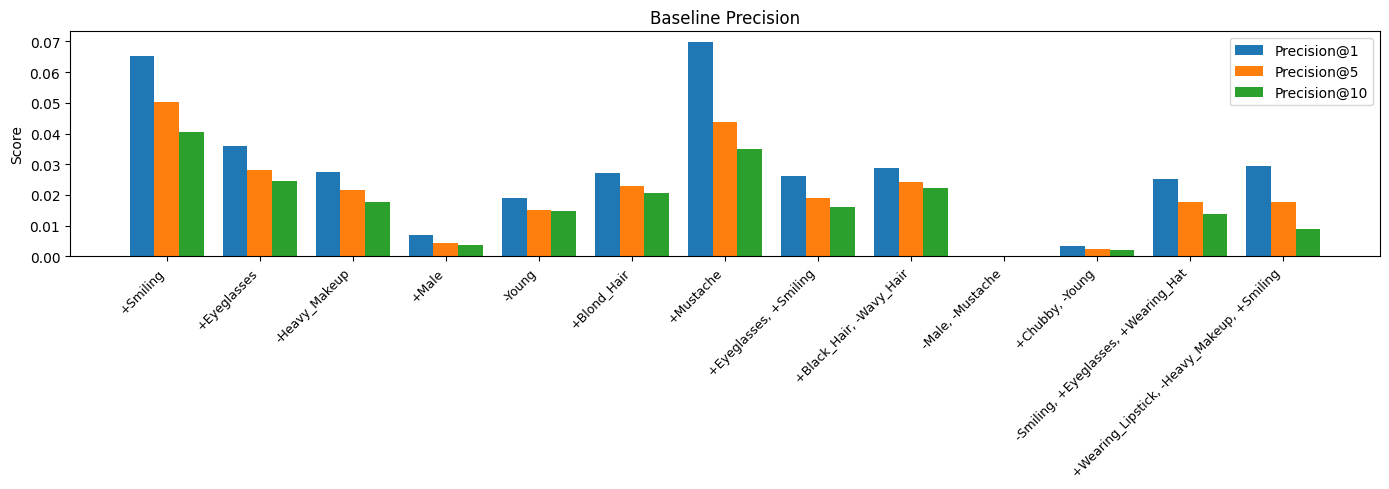

In [21]:
plot_per_query(baseline_avg, "Baseline Recall", metrics=["Recall@1", "Recall@5", "Recall@10"])
plot_per_query(baseline_avg, "Baseline Precision", metrics=["Precision@1", "Precision@5", "Precision@10"])

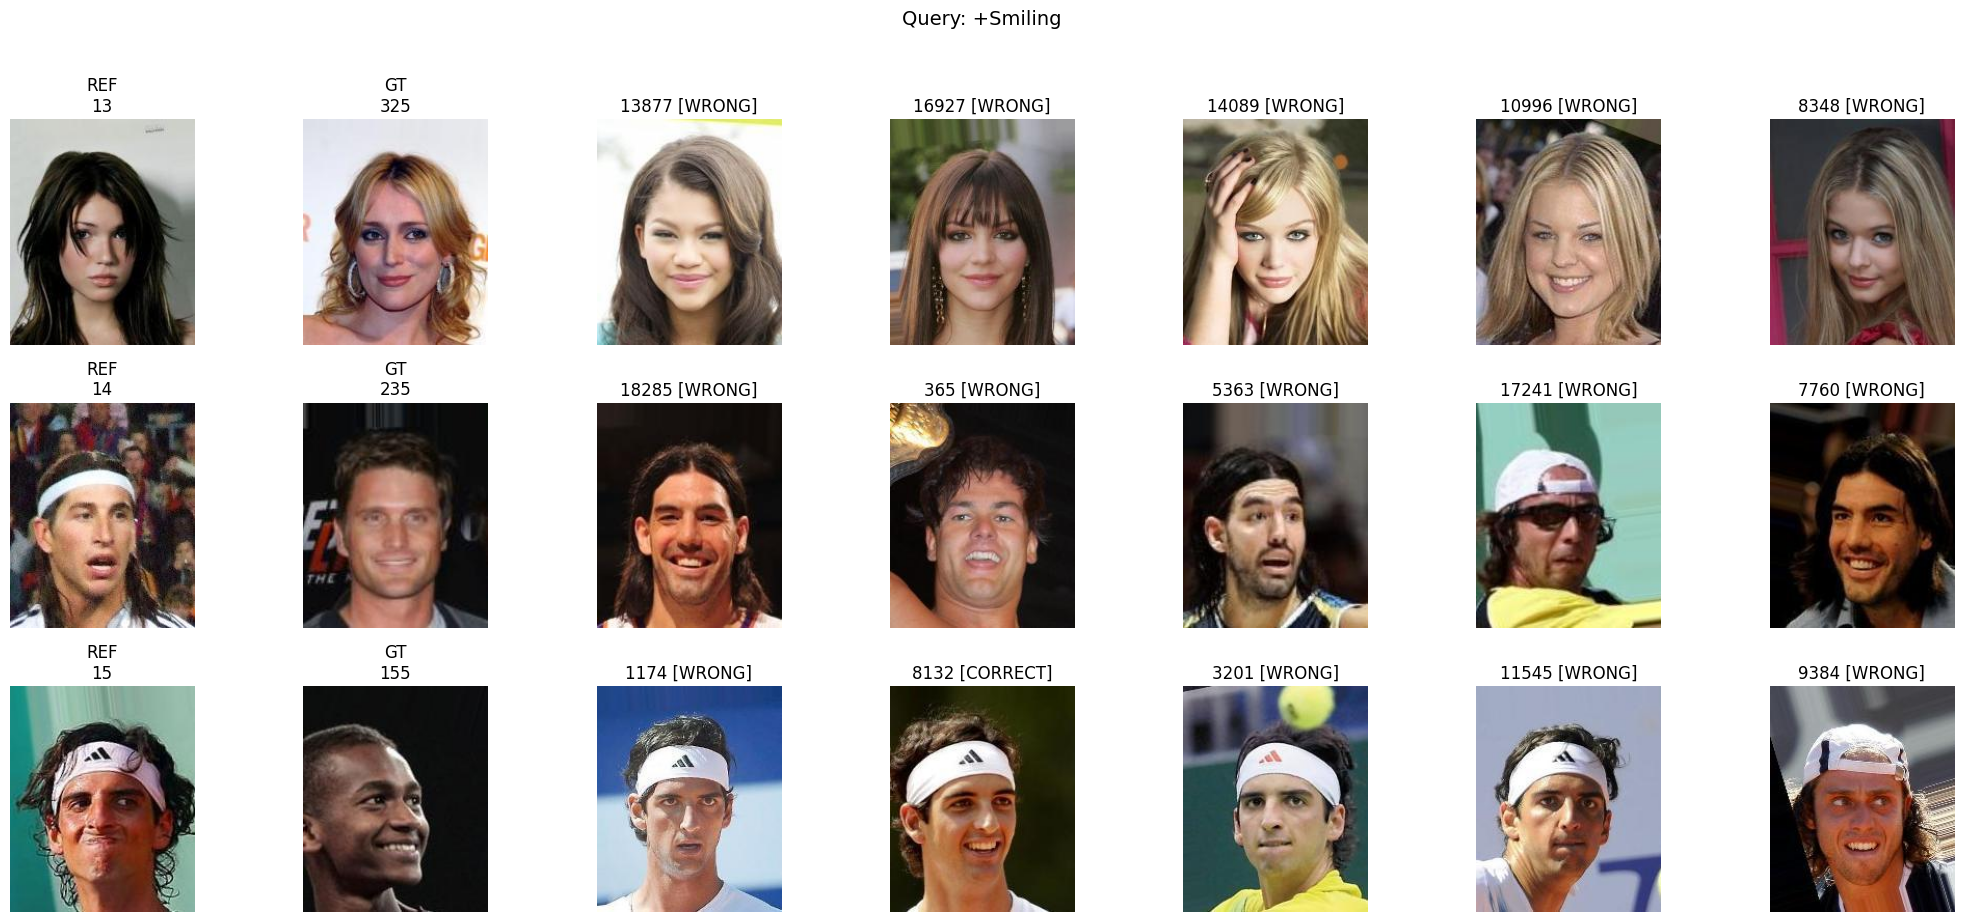

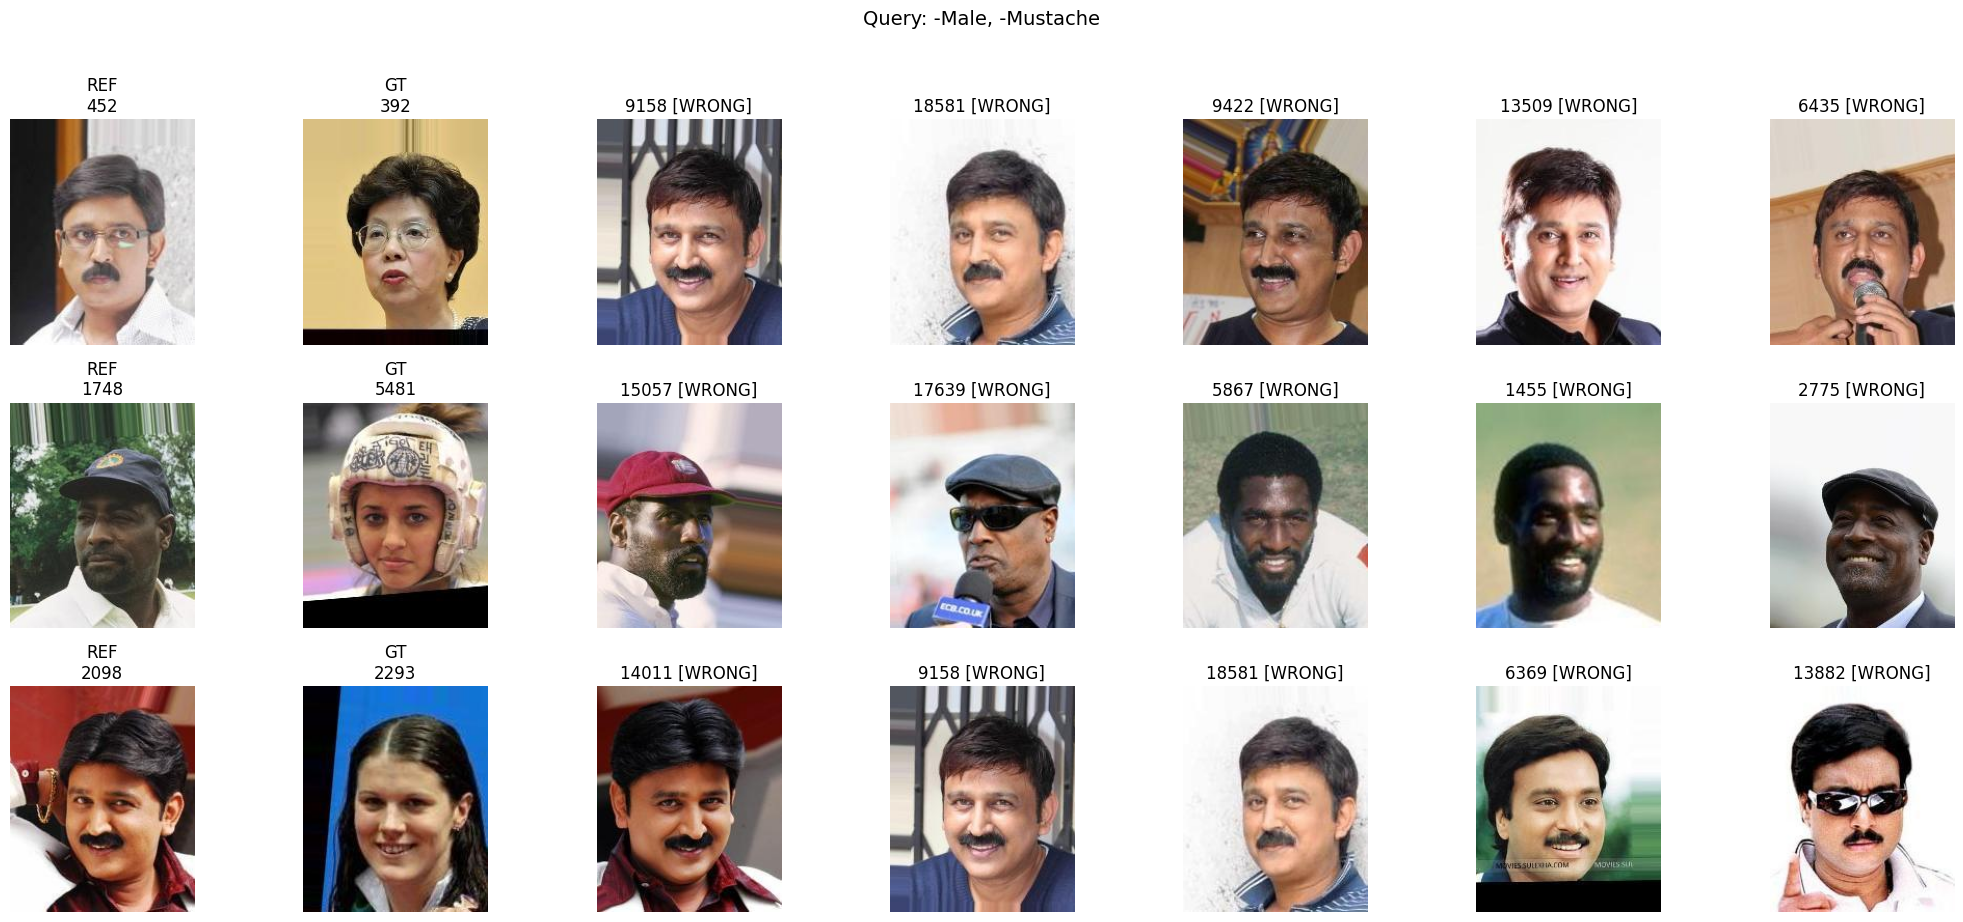

In [38]:
plot_qualitative(baseline_qualitative, "+Smiling")
plot_qualitative(baseline_qualitative, "-Male, -Mustache")